Упражнение 1

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sympy import symbols, limit, oo, sin, sqrt, exp, lambdify

x = symbols('x')
z = np.linspace(-4, 4, 400)

#для лимитов
F1_sym = (exp(4*x) - 1) / (1 - exp(5*x))
F2_sym = (-x**2 - 3*x - 7) * exp(2*x)
F3_sym = sin(x) / (sqrt(x + 1) - sqrt(2*x + 1))

print("lim f1 =", limit(F1_sym, x, oo))
print("lim f2 =", limit(F2_sym, x, 1))
print("lim f3 =", limit(F3_sym, x, 0))

#для графиков
f1 = lambdify(x, F1_sym, 'numpy')
f2 = lambdify(x, F2_sym, 'numpy')
f3 = lambdify(x, F3_sym, 'numpy')

fig, axes = plt.subplots(2, 2, figsize=(12, 9))


axes[0, 0].plot(z, f1(z), 'g')
axes[0, 0].set_title("euler's number")
axes[0, 0].grid(True)

axes[0, 1].plot(z, f2(z), 'm')
axes[0, 1].set_title("x --> 1")
axes[0, 1].grid(True)

with np.errstate(invalid='ignore'):
    axes[1, 0].plot(z, f3(z), 'k')
axes[1, 0].set_title("sin i sqrt")
axes[1, 0].grid(True)

axes[1, 1].axis('off')
plt.show()

lim f1 = 0
lim f2 = -11*exp(2)
lim f3 = -2


KeyboardInterrupt: 

Упражнение 2

a) lim x->0- : oo
a) lim x->0+ : 0
b) lim x->0- : -2/pi
b) lim x->0+ : 2/pi
c) lim x->0  : 0
g) lim x->0  : -oo
g) lim x->1  : -pi/2


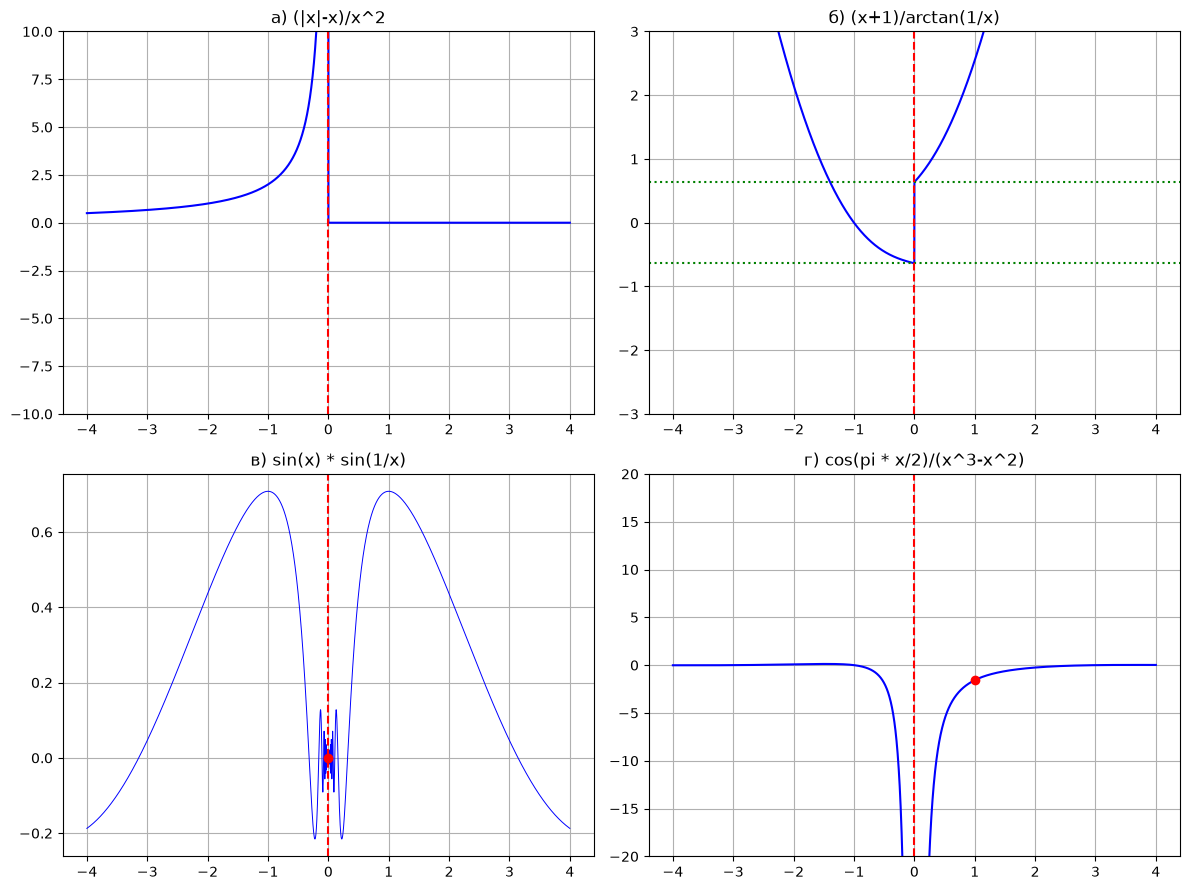

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import (symbols, limit, sin, cos, atan, Abs, pi,
                   lambdify)

x = symbols('x', real=True)

F_a = (Abs(x) - x) / x**2
F_b = (x + 1) / atan(1/x)
F_c = sin(x) * sin(1/x)
F_g = cos(pi * x / 2) / (x**3 - x**2)


print("a) lim x->0- :", limit(F_a, x, 0, '-'))
print("a) lim x->0+ :", limit(F_a, x, 0, '+'))
#x < 0: -2/x --> lim(f(x)) = oo
#x > 0: 0/x^2 --> lim(f(x)) = 0

print("b) lim x->0- :", limit(F_b, x, 0, '-'))
print("b) lim x->0+ :", limit(F_b, x, 0, '+'))

print("c) lim x->0  :", limit(F_c, x, 0))

print("g) lim x->0  :", limit(F_g, x, 0))
print("g) lim x->1  :", limit(F_g, x, 1))

#преобразование для работы с графиками
f_a = lambdify(x, F_a, 'numpy')
f_b = lambdify(x, F_b, 'numpy')
f_c = lambdify(x, F_c, 'numpy')
f_g = lambdify(x, F_g, 'numpy')


fig, axes = plt.subplots(2, 2, figsize=(12, 9))

z = np.linspace(-4, 4, 4000)

with np.errstate(all='ignore'):
    y_a = f_a(z); y_b = f_b(z); y_c = f_c(z); y_g = f_g(z)


axes[0, 0].plot(z, y_a, 'b')
axes[0, 0].set_title("а) (|x|-x)/x^2")
axes[0, 0].set_ylim(-10, 10)
#x = 0 выколота

axes[0, 1].plot(z, y_b, 'b')
axes[0, 1].axhline( 2/np.pi, color='g', ls=':') #горизонтальная линия
axes[0, 1].axhline(-2/np.pi, color='g', ls=':')
axes[0, 1].set_title("б) (x+1)/arctan(1/x)")
axes[0, 1].set_ylim(-3, 3)

axes[1, 0].plot(z, y_c, 'b', lw=0.7)
axes[1, 0].scatter([0], [0], color='red', zorder=5)
axes[1, 0].set_title("в) sin(x) * sin(1/x)")

axes[1, 1].plot(z, y_g, 'b')
axes[1, 1].scatter([1], [-np.pi/2], color='red', zorder=5)
axes[1, 1].set_ylim(-20, 20)
axes[1, 1].set_title("г) cos(pi * x/2)/(x^3-x^2)")

for ax in axes.ravel():     #раскладывает многомерный массив в одномерный
    ax.grid(True)
    ax.axvline(0, color='r', ls='--')    #вертикальная линия

plt.tight_layout()
plt.show()

Упражнение 3

а) lim x->3  : oo
а) lim x->-3 : oo
а) k = 4
а) b = 5
б) lim x->-oo : 0
б) lim x->+oo : oo


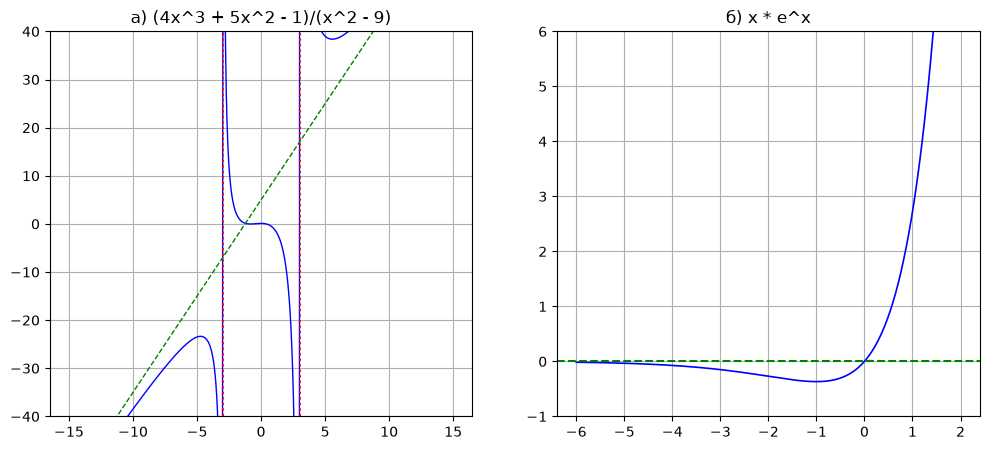

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols, limit, oo, exp, lambdify

x = symbols('x')

F1 = (4*x**3 + 5*x**2 - 1) / (x**2 - 9)
print("а) lim x->3  :", limit(F1, x, 3))
print("а) lim x->-3 :", limit(F1, x, -3))
print("а) k =", limit(F1/x, x, oo))
print("а) b =", limit(F1 - 4*x, x, oo))

F2 = x * exp(x)
print("б) lim x->-oo :", limit(F2, x, -oo))
print("б) lim x->+oo :", limit(F2, x, oo))

f1 = lambdify(x, F1, 'numpy')
f2 = lambdify(x, F2, 'numpy')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

z = np.linspace(-15, 15, 4000)
z = z[np.abs(np.abs(z) - 3) > 0.05] #выкидываем асимптоты
with np.errstate(all='ignore'):
    y = f1(z)       #новый нумпай массив

axes[0].plot(z, y, 'b', lw=1, label='f(x)')
axes[0].plot(z, 4*z + 5, 'g--', lw=1, label='y = 4x + 5')
axes[0].axvline( 3, color='r', ls=':', label='x = 3')
axes[0].axvline(-3, color='r', ls=':', label='x = -3')
axes[0].set_ylim(-40, 40)
axes[0].set_title("а) (4x^3 + 5x^2 - 1)/(x^2 - 9)")


z = np.linspace(-6, 2, 1000)
y = f2(z)

axes[1].plot(z, y, 'b', lw=1.2, label='f(x) = x * e^x')
axes[1].axhline(0, color='g', ls='--', label='y = 0 (при x -> −oo)')
axes[1].set_ylim(-1, 6)
axes[1].set_title("б) x * e^x")

for a in axes:
    a.grid(True)

plt.show()

Упражнение 4

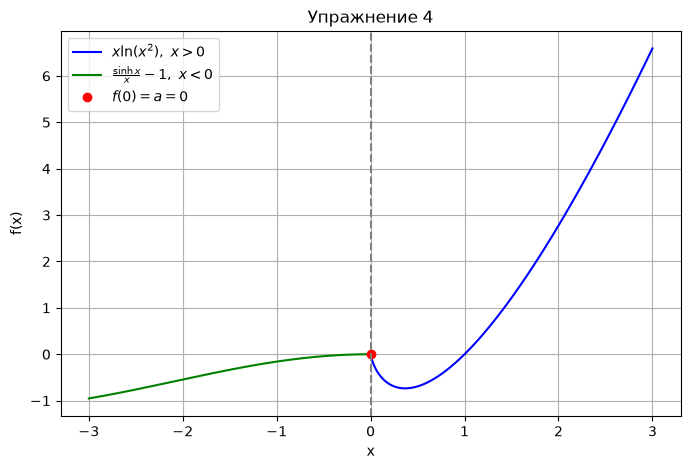

In [9]:
import matplotlib.pyplot as plt
import numpy as np

x1 = np.linspace(0.01, 3, 500)
y1 = x1 * np.log(x1**2)
x2 = np.linspace(-3, -0.01, 500)
y2 = np.sin(x2) / x2 - 1

plt.figure(figsize=(8, 5))
plt.plot(x1, y1, 'b', label=r'$x\ln(x^2),\ x>0$')
plt.plot(x2, y2, 'g', label=r'$\frac{\sinh x}{x}-1,\ x<0$')
plt.plot(0, 0, 'ro', label=r'$f(0)=a=0$')
plt.axvline(x=0, color='gray', linestyle='--')
plt.grid(True)
plt.title('Упражнение 4')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.show()

Упражнение 5

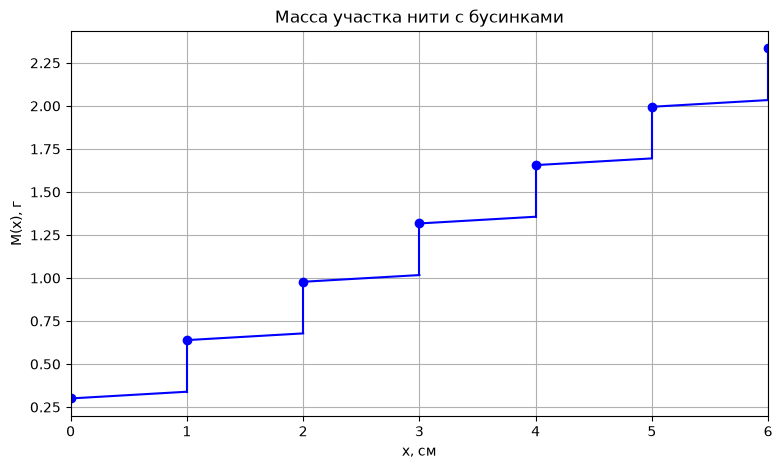

In [10]:
import matplotlib.pyplot as plt
import numpy as np

p = 0.039
m = 0.3

plt.figure(figsize=(9, 5))

for k in range(6):
    x = np.linspace(k, k + 1, 100)
    y = p * x + m * (k + 1)
    plt.plot(x, y, 'b')

for k in range(1, 7):
    y1 = p * k + m * k
    y2 = p * k + m * (k + 1)
    plt.plot([k, k], [y1, y2], 'b')

x = np.arange(0, 7)
y = p * x + m * (x + 1)
plt.plot(x, y, 'bo')

plt.grid()
plt.title('Масса участка нити с бусинками')
plt.xlabel('x, см')
plt.ylabel('M(x), г')
plt.xlim(0, 6)
plt.show()